In [ ]:
import numpy as np  
import pandas as pd  
import matplotlib.pyplot as plt 
import seaborn as sns  

In [ ]:
titanic_df = pd.read_csv("./train.csv")  # 타이타닉 CSV를 DataFrame으로 읽음
titanic_df.head()  # 데이터의 처음 5행을 확인

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
titanic_df.info()  # 전체 구조를 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
titanic_df["Cabin"].head()  # 객실 번호의 처음 5개 값을 확인

0     NaN
1     C85
2     NaN
3    C123
4     NaN
Name: Cabin, dtype: object

In [ ]:
titanic_df["Cabin"].value_counts() # 객실 번호별 승객 수를 확인

B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
              ..
E34            1
C7             1
C54            1
E36            1
C148           1
Name: Cabin, Length: 147, dtype: int64

In [ ]:
titanic_df["Embarked"].head()  # 항구의 처음 5개 값을 확인

0    S
1    C
2    S
3    S
4    S
Name: Embarked, dtype: object

In [ ]:
# 결측치를 채움 / 나이는 평균값, 객실과 항구는 'N'을 사용
# 마지막 줄에서 남아 있는 전체 결측치 개수를 확인

titanic_df["Age"] = titanic_df["Age"].fillna(titanic_df["Age"].mean())  # 나이 결측치를 전체 평균 나이로 채움
titanic_df["Cabin"] = titanic_df["Cabin"].fillna("N")  # 객실 결측치를 N
titanic_df["Embarked"] = titanic_df["Embarked"].fillna("N")  # 승선 항구 결측치를 N
titanic_df.isnull().sum().sum()  # 모든 열에 남은 결측치 수를 합산

0

In [ ]:
titanic_df["Sex"].value_counts() # 성별 승객 수를 확인

male      577
female    314
Name: Sex, dtype: int64

In [ ]:
titanic_df["Cabin"].value_counts()  # N을 포함한 객실 번호별 승객 수

N              687
C23 C25 C27      4
G6               4
B96 B98          4
C22 C26          3
              ... 
E34              1
C7               1
C54              1
E36              1
C148             1
Name: Cabin, Length: 148, dtype: int64

In [ ]:
titanic_df["Embarked"].value_counts()  # N을 포함한 항구별 승객 수

S    644
C    168
Q     77
N      2
Name: Embarked, dtype: int64

In [ ]:
# 객실 번호의 첫 글자만 남겨 객실 구역을 나타내는 범주 단순화

titanic_df["Cabin"] = titanic_df["Cabin"].str[:1]  # 객실 번호에서 첫 글자만 추출
titanic_df["Cabin"].head()  # 변환된 객실 구역의 처음 5개 확인

0    N
1    C
2    N
3    C
4    N
Name: Cabin, dtype: object

In [ ]:
titanic_df.groupby(["Sex", "Survived"])["Survived"].count()  # 성별·생존 여부 조합별 인원수를 셈

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

<AxesSubplot: xlabel='Sex', ylabel='Survived'>

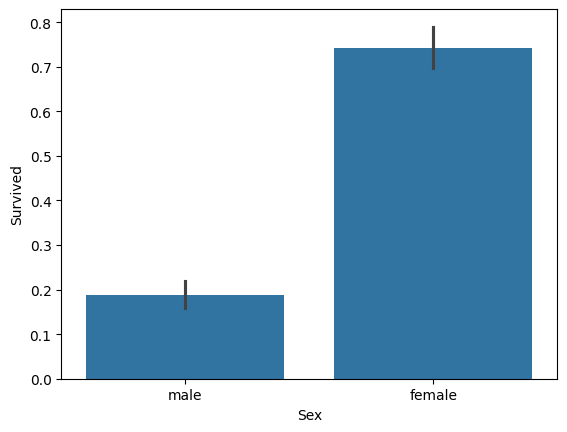

In [ ]:
sns.barplot(x = "Sex", y = "Survived", data = titanic_df)  # 막대 높이는 성별 평균 생존율

<AxesSubplot: xlabel='Pclass', ylabel='Survived'>

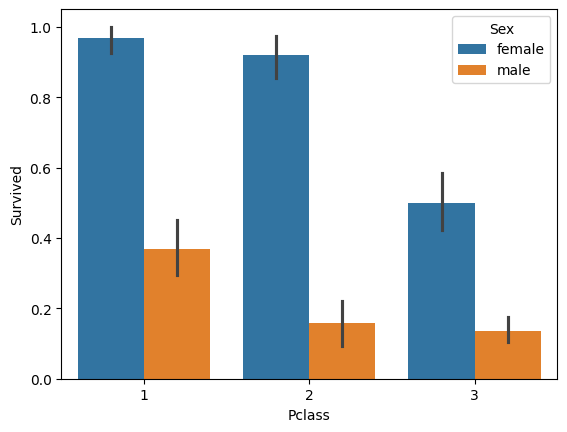

In [ ]:
# 객실 등급별 평균 생존율을 성별로 나누어 비교

sns.barplot(x = "Pclass", y = "Survived", hue = "Sex", data = titanic_df)

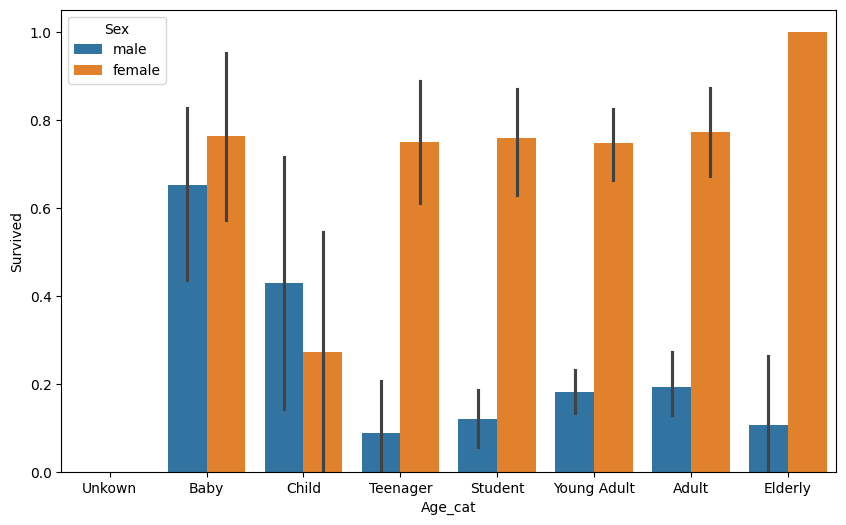

In [ ]:
# 나이를 구간별 범주로 변환해 성별·연령대별 생존율을 비교

def get_category(age):  # 숫자 나이를 연령대 문자열로 바꾸는 함수
    cat = ''  # 반환할 연령대 이름을 초기화
    if age <= -1: cat = "Unknown" 
    elif age <= 5: cat = "Baby" 
    elif age <= 12: cat = "Child"  
    elif age <= 18: cat = "Teenager"  
    elif age <= 25: cat = "Student"  
    elif age <= 35: cat = "Young Adult" 
    elif age <= 60: cat = "Adult"  
    else: cat = "Elderly"  

    return cat  # 연령대 이름을 반환

group_names = ["Unkown", "Baby", "Child", "Teenager", "Student", "Young Adult", "Adult", "Elderly"]
titanic_df["Age_cat"] = titanic_df["Age"].apply(lambda x : get_category(x))  # 모든 승객의 나이를 연령대로 변환

plt.figure(figsize = (10, 6)) 
sns.barplot(x = "Age_cat", y = "Survived", hue = "Sex",
            data = titanic_df, order = group_names)  # 지정한 연령대 생존율

titanic_df.drop("Age_cat", axis = 1, inplace = True)

In [ ]:
# Cabin, Sex, Embarked의 문자열 범주를 숫자로 변환
# 각 열마다 별도의 LabelEncoder를 학습해 원본 열을 인코딩 값으로 교체

from sklearn import preprocessing

def encode_features(df):  # 선택한 문자열 열을 숫자로 바꾸는 함수
    features = ["Cabin", "Sex", "Embarked"]  # 숫자로 바꿀 범주형 열 목록
    for feature in features:
        le = preprocessing.LabelEncoder()  # 현재 열을 위한 새 인코더를 만듬
        le = le.fit(df[feature])  # 현재 열의 범주와 숫자 대응
        df[feature] = le.transform(df[feature])  # 문자 범주를 정수로 교체
    return df  # 변환된 DataFrame을 반환

titanic_df = encode_features(titanic_df)  # 타이타닉 데이터의 세 범주형 열을 변환
titanic_df.head()  # 인코딩된 데이터의 처음 5행을 확인

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


In [ ]:
titanic_df["Cabin"].value_counts()  # 숫자로 인코딩된 객실 구역별 승객 수

7    687
2     59
1     47
3     33
4     32
0     15
5     13
6      4
8      1
Name: Cabin, dtype: int64

In [ ]:
titanic_df["Sex"].value_counts()  # 숫자로 인코딩된 성별 승객 수

1    577
0    314
Name: Sex, dtype: int64

In [ ]:
titanic_df["Embarked"].value_counts()  # 숫자로 인코딩된 항구별 승객 수

3    644
0    168
2     77
1      2
Name: Embarked, dtype: int64

In [ ]:
titanic_df.head()  # 전체 전처리 결과의 처음 5행을 확인

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,7,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,7,3
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2,3
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,7,3


In [ ]:
# 모델 학습에 불필요한 열을 삭제

titanic_df.drop(["PassengerId", "Name", "Ticket"], axis = 1, inplace = True)

In [ ]:
titanic_df.head()  # 제거 확인

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,1,22.0,1,0,7.2500,7,3
1,1,1,0,38.0,1,0,71.2833,2,0
2,1,3,0,26.0,0,0,7.9250,7,3
3,1,1,0,35.0,1,0,53.1000,2,3
4,0,3,1,35.0,0,0,8.0500,7,3


In [ ]:
titanic_df["Fare"].isna().sum()  # 요금(Fare) 열에 결측치 확인

0

In [ ]:
# 생존 여부를 정답(y)으로 분리하고 나머지 열을 입력 특성(X)으로 만듬

y_titanic_df = titanic_df["Survived"]  # 예측할 생존 여부를 정답 데이터로 저장
X_titanic_df = titanic_df.drop("Survived", axis = 1)  # 생존 여부를 제외한 열을 입력 특성으로 저장

In [ ]:
X_titanic_df.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,3,1,22.0,1,0,7.2500,7,3
1,1,0,38.0,1,0,71.2833,2,0
2,3,0,26.0,0,0,7.9250,7,3
3,1,0,35.0,1,0,53.1000,2,3
4,3,1,35.0,0,0,8.0500,7,3


In [ ]:
y_titanic_df.head()  # 정답 데이터의 처음 5개 값을 확인

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [ ]:
# 입력 특성과 정답을 학습용 80%, 테스트용 20%로 나눔

from sklearn.model_selection import train_test_split 

X_train, X_test, y_train, y_test = train_test_split(X_titanic_df,
                y_titanic_df, test_size = 0.2, random_state = 11)  # 20%를 테스트용으로 사용하고 분할 결과 고정

In [ ]:
# 결정 트리, 랜덤 포레스트, 로지스틱 회귀를 같은 데이터로 학습
# 각 모델의 테스트 예측 정확도를 계산해 성능을 비교

from sklearn.tree import DecisionTreeClassifier  
from sklearn.ensemble import RandomForestClassifier  
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score  

dt_clf = DecisionTreeClassifier(random_state = 11)  # 재현 가능한 결정 트리 모델을 만듬
rf_clf = RandomForestClassifier(random_state = 11, n_jobs=-1)  # 랜덤 포레스트를 만듬 오류떠서 n_jobs=-1 추가함
lr_clf = LogisticRegression(solver="liblinear")  # 작은 이진 분류에 적합한 최적화 방식을 사용

dt_clf.fit(X_train, y_train)  # 결정 트리를 학습
dt_pred = dt_clf.predict(X_test)  # 결정 트리로 테스트 생존 여부를 예측
print("결정트리정확도 :", accuracy_score(y_test, dt_pred))  # 결정 트리의 정확도

rf_clf.fit(X_train, y_train)  # 랜덤 포레스트를 학습
rf_pred = rf_clf.predict(X_test)  # 랜덤 포레스트로 테스트 생존 여부를 예측
print("랜덤포레스트정확도 :", accuracy_score(y_test, rf_pred))  # 랜덤 포레스트의 정확도

lr_clf.fit(X_train, y_train)  # 로지스틱 회귀를 학습
lr_pred = lr_clf.predict(X_test)  # 로지스틱 회귀로 테스트 생존 여부를 예측
print("로직스틱회귀정확도 :", accuracy_score(y_test, lr_pred))  # 로지스틱 회귀의 정확도

결정트리정확도 : 0.7877094972067039
랜덤포레스트정확도 : 0.8547486033519553
로직스틱회귀정확도 : 0.8659217877094972


In [ ]:
# 전달받은 모델을 일반 K-Fold 방식으로 5번 학습·검증하는 함수를 정의
# 각 회차의 정확도와 전체 평균 정확도를 출력한 뒤 결정 트리에 적용

from sklearn.model_selection import KFold 

def exec_kfold(clf, folds = 5):  # 모델과 폴드 수를 받아 교차검증하는 함수
    kfold = KFold(n_splits = folds)  # 지정한 개수만큼 폴드를 만듬
    scores = []  # 폴드별 정확도를 저장

    for iter_count, (train_index, test_index) in enumerate(kfold.split(X_titanic_df)):  # 각 폴드의 회차와 행 번호를 받음
        X_train, X_test = X_titanic_df.values[train_index], X_titanic_df.values[test_index]  # 입력 특성을 학습·검증용 배열로 나눔
        y_train, y_test = y_titanic_df.values[train_index], y_titanic_df.values[test_index]  # 정답을 같은 행 번호로 나눔

        clf.fit(X_train, y_train)  # 전달받은 모델을 현재 학습 세트로 학습
        predictions = clf.predict(X_test)  # 현재 검증 세트의 생존 여부를 예측
        accuracy = accuracy_score(y_test, predictions)  # 현재 폴드의 정확도를 계산
        scores.append(accuracy)  # 정확도를 목록에 추가
        print("교차검증정확도 :", accuracy)  # 현재 폴드의 정확도를 출력
    mean_score = np.mean(scores)  # 모든 폴드 정확도의 평균을 계산
    print("평균 정확도 :", mean_score)  # 평균 교차검증 정확도를 출력

exec_kfold(dt_clf, 5)  # 결정 트리를 5겹 교차검증

교차검증정확도 : 0.7541899441340782
교차검증정확도 : 0.7808988764044944
교차검증정확도 : 0.7865168539325843
교차검증정확도 : 0.7696629213483146
교차검증정확도 : 0.8202247191011236
평균 정확도 : 0.782298662984119


In [ ]:
exec_kfold(rf_clf, 5)  # 랜덤 포레스트를 5겹 교차검증

교차검증정확도 : 0.7932960893854749
교차검증정확도 : 0.8089887640449438
교차검증정확도 : 0.8370786516853933
교차검증정확도 : 0.7752808988764045
교차검증정확도 : 0.8595505617977528
평균 정확도 : 0.8148389931579938


In [ ]:
exec_kfold(lr_clf, 5)  # 로지스틱 회귀를 5겹 교차검증

교차검증정확도 : 0.7932960893854749
교차검증정확도 : 0.7921348314606742
교차검증정확도 : 0.7752808988764045
교차검증정확도 : 0.7471910112359551
교차검증정확도 : 0.8426966292134831
평균 정확도 : 0.7901198920343984


In [ ]:
# GridSearchCV로 결정 트리의 깊이와 분할 조건 조합을 탐색
# 최적 모델을 테스트 데이터에 적용해 최종 정확도를 확인

from sklearn.model_selection import GridSearchCV 

parameters = {"max_depth": [2, 3, 5, 10],  # 트리 깊이를 지정
              "min_samples_split": [2, 3, 5],  # 노드를 나눌 최소 샘플 수
              "min_samples_leaf": [1, 5, 8]  # 리프 노드가 가질 최소 샘플 수 
              }

grid_dclf = GridSearchCV(dt_clf, param_grid = parameters, scoring = "accuracy", cv = 5)  # 각 조합을 5겹 정확도로 평가
grid_dclf.fit(X_train, y_train)  # 옵션을 탐색하고 최적 결정 트리를 재학습

print(grid_dclf.best_params_)  # 가장 좋은 옵션 조합을 출력
print(grid_dclf.best_score_)  # 최적 조합의 평균 교차검증 정확도를 출력

best_dclf = grid_dclf.best_estimator_  # 최적 옵션으로 학습된 모델

dpredictions = best_dclf.predict(X_test)  # 최적 모델로 테스트 생존 여부를 예측
accuracy = accuracy_score(y_test, dpredictions)  # 최종 테스트 정확도
print(accuracy)  # 최종 정확도

{'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
0.7991825076332119
0.8715083798882681
